In [3]:
#Importing Numpy and Pandas
import numpy as np
import pandas as pd
#Reading Data
barcelona=pd.read_csv("C:\\Users\\Teju\\Desktop\\barcelona\\BarcelonaDataset-master\\accidents_2017.csv")
barcelona.head()

,Id,District Name,Neighborhood Name,Street,Weekday,Month,Day,Hour,Part of the day,Mild injuries,Serious injuries,Victims,Vehicles involved,Longitude,Latitude
0,2017S008429,Unknown,Unknown,Número 27 ...,Friday,October,13,8,Morning,2,0,2,2,2.125624,41.340045
1,2017S007316,Unknown,Unknown,Número 3 Zona Franca / Número 50 Zona Franca ...,Friday,September,1,13,Morning,2,0,2,2,2.120452,41.339426
2,2017S010210,Unknown,Unknown,Litoral (Besòs) ...,Friday,December,8,21,Afternoon,5,0,5,2,2.167356,41.360885
3,2017S006364,Unknown,Unknown,Número 3 Zona Franca ...,Friday,July,21,2,Night,1,0,1,2,2.124529,41.337668
4,2017S004615,Sant Martí,el Camp de l'Arpa del Clot,Las Navas de Tolosa ...,Thursday,May,25,14,Afternoon,1,0,1,3,2.185272,41.416365


In [4]:
#Data Visualization
#1.Unknown values in Distric Name
#2.Hour of day not matching with part of the day...(13 ie 1pm is showed as Morning, 21 ie 9PM is shown as Afternoon)

#Imputing District Name Data using Latitiude and Longitude Information
#reverse_geocoder is a function to get district name using Latitudes and Longitudes
import reverse_geocoder as rg
import pprint

def getdtname(row):
    coordinate = row['latitude'] , row['longitude']
    result = rg.search(coordinates)
    return result[0]['name']
coordinates =(2.125, 41.340)
a=reverseGeocode(coordinates)
a



Loading formatted geocoded file...


[OrderedDict([('lat', '2.34464'),
              ('lon', '42.27644'),
              ('name', 'Baardheere'),
              ('admin1', 'Gedo'),
              ('admin2', ''),
              ('cc', 'SO')])]

In [5]:
a[0]['name']

'Baardheere'

In [ ]:
barcelona['District Name'] = barcelona.apply(lambda x : get_dt_name(x), axis =1 )

In [6]:
for i in range(barcelona.shape[0]):
    if barcelona['District Name'][i] == 'Unknown':
        code= reverseGeocode((barcelona.Longitude[i], barcelona.Latitude[i]))
        barcelona['District Name'][i]= code[0]['name']
barcelona.head()

c:\users\teju\appdata\local\programs\python\python36\lib\site-packages\ipykernel_launcher.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  after removing the cwd from sys.path.


,Id,District Name,Neighborhood Name,Street,Weekday,Month,Day,Hour,Part of the day,Mild injuries,Serious injuries,Victims,Vehicles involved,Longitude,Latitude
0,2017S008429,Baardheere,Unknown,Número 27 ...,Friday,October,13,8,Morning,2,0,2,2,2.125624,41.340045
1,2017S007316,Baardheere,Unknown,Número 3 Zona Franca / Número 50 Zona Franca ...,Friday,September,1,13,Morning,2,0,2,2,2.120452,41.339426
2,2017S010210,Baardheere,Unknown,Litoral (Besòs) ...,Friday,December,8,21,Afternoon,5,0,5,2,2.167356,41.360885
3,2017S006364,Baardheere,Unknown,Número 3 Zona Franca ...,Friday,July,21,2,Night,1,0,1,2,2.124529,41.337668
4,2017S004615,Sant Martí,el Camp de l'Arpa del Clot,Las Navas de Tolosa ...,Thursday,May,25,14,Afternoon,1,0,1,3,2.185272,41.416365


In [7]:
#Part of the day correction

from sys import stdout


def get_part_of_day(hour):
    return (
        "morning" if 5 <= hour <= 11
        else
        "afternoon" if 12 <= hour <= 17
        else
        "evening" if 18 <= hour <= 22
        else
        "night"
    )
for i in range(0, 24):
    stdout.write('hour {0} is {1}\n'.format(i, get_part_of_day(i)))

hour 0 is night
hour 1 is night
hour 2 is night
hour 3 is night
hour 4 is night
hour 5 is morning
hour 6 is morning
hour 7 is morning
hour 8 is morning
hour 9 is morning
hour 10 is morning
hour 11 is morning
hour 12 is afternoon
hour 13 is afternoon
hour 14 is afternoon
hour 15 is afternoon
hour 16 is afternoon
hour 17 is afternoon
hour 18 is evening
hour 19 is evening
hour 20 is evening
hour 21 is evening
hour 22 is evening
hour 23 is night


In [8]:
for i in range(barcelona.shape[0]):
    code= get_part_of_day((barcelona.Hour[i]))
    barcelona['Part of the day'][i]= code

c:\users\teju\appdata\local\programs\python\python36\lib\site-packages\ipykernel_launcher.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: http://pandas.pydata.org/pandas-docs/stable/indexing.html#indexing-view-versus-copy
  This is separate from the ipykernel package so we can avoid doing imports until


In [9]:
barcelona.head()

,Id,District Name,Neighborhood Name,Street,Weekday,Month,Day,Hour,Part of the day,Mild injuries,Serious injuries,Victims,Vehicles involved,Longitude,Latitude
0,2017S008429,Baardheere,Unknown,Número 27 ...,Friday,October,13,8,morning,2,0,2,2,2.125624,41.340045
1,2017S007316,Baardheere,Unknown,Número 3 Zona Franca / Número 50 Zona Franca ...,Friday,September,1,13,afternoon,2,0,2,2,2.120452,41.339426
2,2017S010210,Baardheere,Unknown,Litoral (Besòs) ...,Friday,December,8,21,evening,5,0,5,2,2.167356,41.360885
3,2017S006364,Baardheere,Unknown,Número 3 Zona Franca ...,Friday,July,21,2,night,1,0,1,2,2.124529,41.337668
4,2017S004615,Sant Martí,el Camp de l'Arpa del Clot,Las Navas de Tolosa ...,Thursday,May,25,14,afternoon,1,0,1,3,2.185272,41.416365


In [10]:

import seaborn as sns
%matplotlib inline
from matplotlib import pyplot as plt
from matplotlib import style


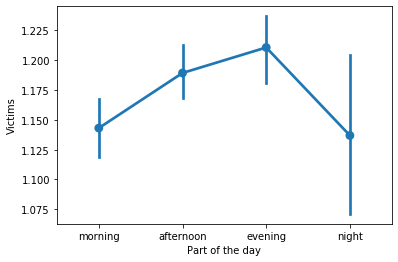

In [11]:
# Victims vs Part of the day
sns.pointplot(x='Part of the day',y='Victims',data=barcelona)
 
#Victims are more in the evening with less variance
#Victims are less in the night with high variance

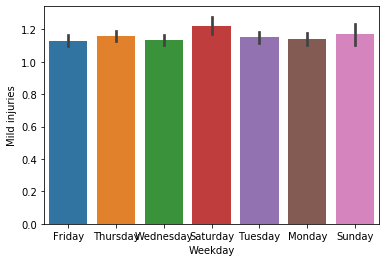

In [12]:
Mild=sns.barplot(x="Weekday", y="Mild injuries", data=barcelona)

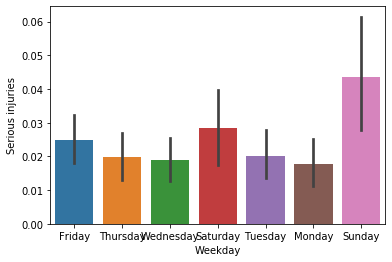

In [13]:
Serious=sns.barplot(x='Weekday', y='Serious injuries', data=barcelona)

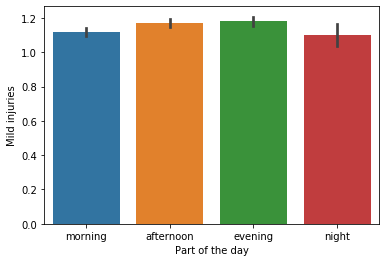

In [14]:
Part=sns.barplot(x="Part of the day", y="Mild injuries", data=barcelona)

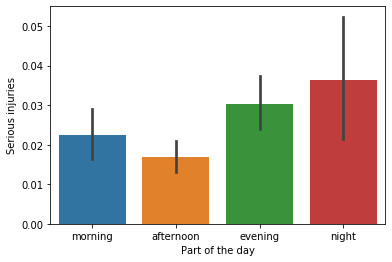

In [15]:
Part2=sns.barplot(x="Part of the day", y="Serious injuries", data=barcelona)

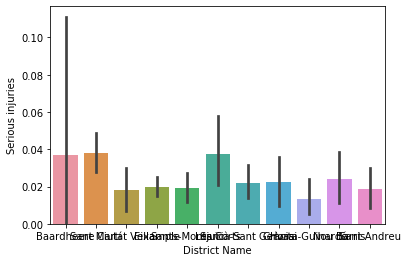

In [16]:
District_Serious=sns.barplot(x="District Name", y="Serious injuries", data=barcelona)

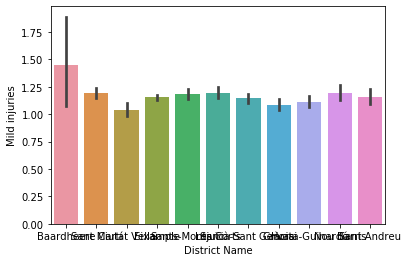

In [17]:
District_Mild=sns.barplot(x="District Name", y="Mild injuries", data=barcelona)

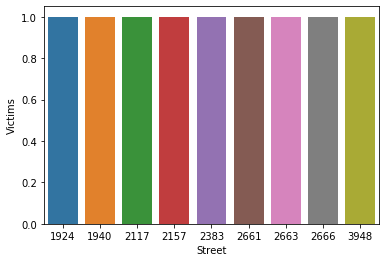

In [46]:
Street=sns.barplot(x="Street", y="Victims", data=barcelona[])

c:\users\teju\appdata\local\programs\python\python36\lib\site-packages\seaborn\axisgrid.py:230: UserWarning: The `size` paramter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


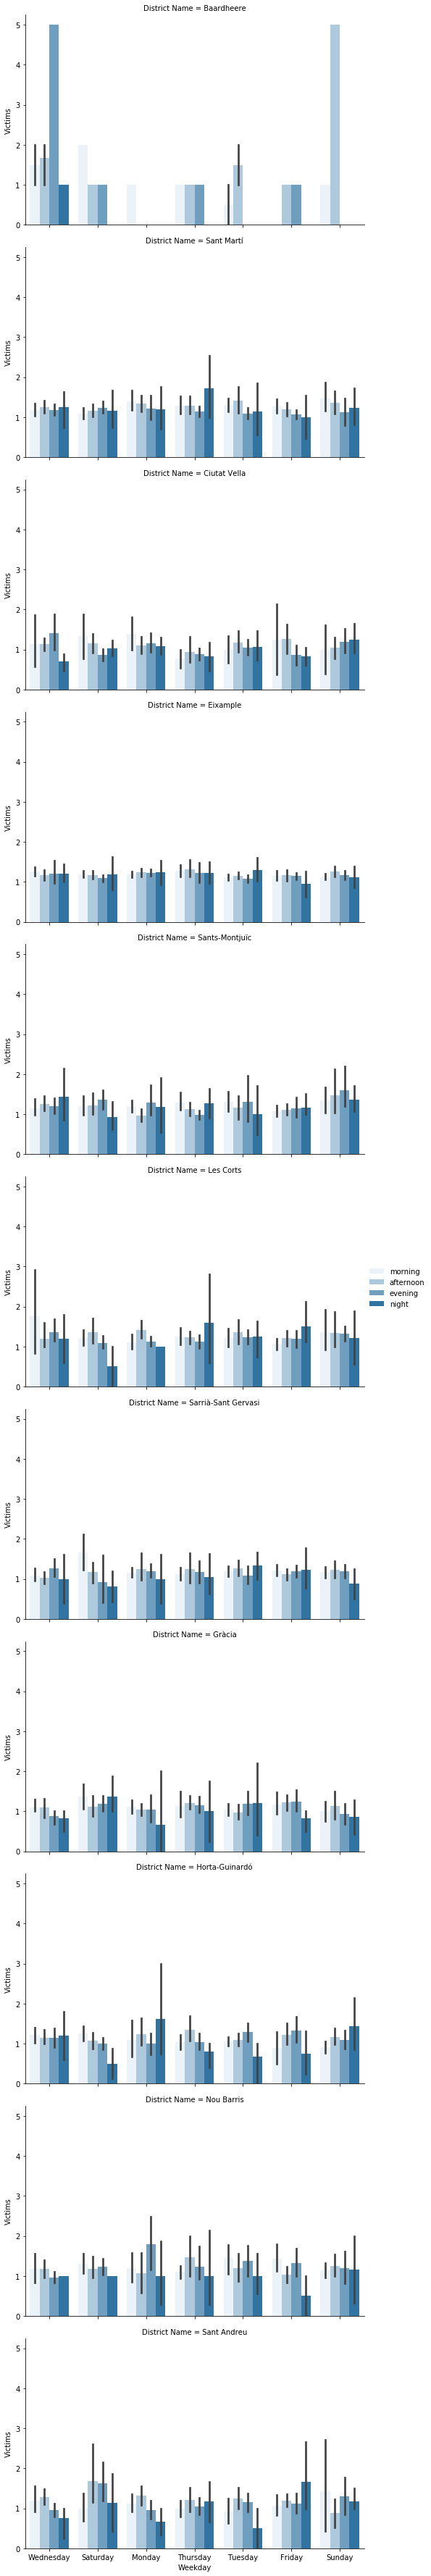

In [19]:
#No of Victims District wise considering weekday and part of day
FacetGrid = sns.FacetGrid(barcelona, row='District Name', size=4.5,aspect=1.6)
FacetGrid.map(sns.barplot, 'Weekday','Victims','Part of the day', palette=None, order=None,hue_order=None)
FacetGrid.add_legend()

In [20]:
#Model Building
#Removing features not required for Model Building
barcelona = barcelona.drop(['Id','Neighborhood Name','Hour','Mild injuries','Serious injuries',
'Vehicles involved','Longitude','Latitude'],axis=1)



In [21]:
barcelona.head()

,District Name,Street,Weekday,Month,Day,Part of the day,Victims
0,Baardheere,Número 27 ...,Friday,October,13,morning,2
1,Baardheere,Número 3 Zona Franca / Número 50 Zona Franca ...,Friday,September,1,afternoon,2
2,Baardheere,Litoral (Besòs) ...,Friday,December,8,evening,5
3,Baardheere,Número 3 Zona Franca ...,Friday,July,21,night,1
4,Sant Martí,Las Navas de Tolosa ...,Thursday,May,25,afternoon,1


In [27]:
#Our target is to predict accident will happen or not if a person drives in a Particular place on a 
#particular day in a particular month 

#Converting Victims into categorical variable
#if victim = 0 --no accident happened 
#if victim is > 0 --accident happened 


barcelona.Victims= barcelona.Victims.map(lambda x: 1 if x != 0 else x)

In [29]:
barcelona.head()

,District Name,Street,Weekday,Month,Day,Part of the day,Victims
0,Baardheere,Número 27 ...,Friday,October,13,morning,1
1,Baardheere,Número 3 Zona Franca / Número 50 Zona Franca ...,Friday,September,1,afternoon,1
2,Baardheere,Litoral (Besòs) ...,Friday,December,8,evening,1
3,Baardheere,Número 3 Zona Franca ...,Friday,July,21,night,1
4,Sant Martí,Las Navas de Tolosa ...,Thursday,May,25,afternoon,1


In [30]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
barcelona.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10339 entries, 0 to 10338
Data columns (total 7 columns):
District Name      10339 non-null object
Street             10339 non-null object
Weekday            10339 non-null object
Month              10339 non-null object
Day                10339 non-null int64
Part of the day    10339 non-null object
Victims            10339 non-null int64
dtypes: int64(2), object(5)
memory usage: 565.5+ KB


In [31]:
#Transforming Categorical to Discrete
for col in barcelona.select_dtypes('object'):
    barcelona[col] = le.fit_transform(barcelona[col] )
barcelona.head()

,District Name,Street,Weekday,Month,Day,Part of the day,Victims
0,0,2661,0,10,13,2,1
1,0,2666,0,11,1,0,1
2,0,2157,0,2,8,1,1
3,0,2663,0,5,21,3,1
4,8,2117,4,8,25,0,1


In [39]:
#Model Building using Logistic Regression
import numpy as np
from sklearn.model_selection import train_test_split
x=barcelona.loc[: , ['District Name','Street','Weekday','Month','Day','Part of the day']]
y=barcelona.loc[: , ['Victims']]

x_train,x_test,y_train,y_test=train_test_split(x,y,train_size=0.7,test_size=0.3,random_state=123)

In [40]:

from sklearn.linear_model import LogisticRegression

In [41]:
logreg = LogisticRegression()
logreg.fit(x_train,y_train)
y_pred=logreg.predict(x_test)


c:\users\teju\appdata\local\programs\python\python36\lib\site-packages\sklearn\linear_model\logistic.py:432: FutureWarning: Default solver will be changed to 'lbfgs' in 0.22. Specify a solver to silence this warning.
  FutureWarning)
c:\users\teju\appdata\local\programs\python\python36\lib\site-packages\sklearn\utils\validation.py:724: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


In [42]:
acc_log = round(logreg.score(x_train, y_train)*100, 2)
print(round(acc_log,2,),"%")

91.14 %


In [43]:
from sklearn.metrics import accuracy_score
acc = accuracy_score(y_pred, y_test)
acc

0.9158607350096711

In [44]:
y_pred[0:50]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1], dtype=int64)

In [45]:
y_test[0:50]

,Victims
1301,1
9945,1
3104,1
8674,1
2832,1
6696,1
943,1
6717,1
5649,1
8770,1
